# CA6127 - Member C: sampling analysis

Project Structure and Generated Outputs

**1.1 Input Data and Configuration

data/captions.json: Selected COCO image captions and associated identifiers.

run_config.json: Experimental configuration saved in the corresponding run directory.

**1.2 Generated Images and Logs

results/images/: Generated images organized by sampler and experiment configuration.

results/generation_log.csv: Per-image generation records, including image paths, sampler settings, and generation time.

results/metrics/fid_reference_images/: Real reference images used for FID evaluation.

**1.3 Evaluation Results (CSV Files)

Main sampler comparison: **results/metrics/

sampler_comparison_summary.csv: Summary of the main sampler comparison.

clip_score_summary.csv: Aggregated CLIP Score results.

clip_scores_per_image.csv: CLIP Score results for individual generated images.

fid_summary.csv: FID evaluation results.

sampler_generation_time_summary.csv: Generation-time comparison across samplers.

Karras schedule ablation

ablation_clip_score_summary.csv: Aggregated CLIP Score results for the ablation experiment.

ablation_clip_scores_per_image.csv: Per-image CLIP Score results for the ablation experiment.

ablation_fid_summary.csv: FID results for the ablation experiment.

Inference-step ablation

dpmpp_steps_clip_score_summary.csv: Aggregated CLIP Score results for different inference-step settings.

dpmpp_steps_clip_scores_per_image.csv: Per-image CLIP Score results for different inference-step settings.

dpmpp_steps_fid_summary.csv: FID results for different inference-step settings.

dpmpp_steps_generation_time.csv: Generation-time results for different inference-step settings.

dpmpp_steps_comparison_summary.csv: Combined comparison of inference-step configurations.

**1.4 Visualization Outputs

The following PNG files summarize the experimental results:

results/visualizations/sampler_comparison_8_prompts.png: Qualitative comparison of generated images.

results/metrics/sampler_comparison_clip_score.png: CLIP Score comparison across samplers.

results/metrics/sampler_comparison_fid.png: FID comparison across samplers.

results/metrics/sampler_generation_time_comparison.png: Generation-time comparison across samplers.

results/visualizations/dpmpp_steps_clip_score.png: CLIP Score comparison across inference steps.

results/visualizations/dpmpp_steps_fid.png: FID comparison across inference steps.

results/visualizations/dpmpp_steps_generation_time.png: Generation-time comparison across inference steps.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#Step 1.1: Check project directory and files
from pathlib import Path

# Project root directory
PROJECT_DIR = Path("/content/drive/MyDrive/CA6127_project")

# Check whether the project directory exists
if not PROJECT_DIR.exists():
    raise FileNotFoundError(
        f"Project directory not found: {PROJECT_DIR}"
    )

print(f"Project directory: {PROJECT_DIR}")
print("=" * 60)

# Files and folders we expect
expected_paths = [
    "data/captions.json",
    "data/images",
    "results/generation_log.csv",
    "results/images/ddim_s30",
    "results/images/euler_s30",
    "results/images/dpmpp_s30",
    "results/images/ddim_s30/run_config.json",
    "results/images/euler_s30/run_config.json",
    "results/images/dpmpp_s30/run_config.json",
]

for relative_path in expected_paths:
    path = PROJECT_DIR / relative_path

    if path.exists():
        status = "OK"
        kind = "directory" if path.is_dir() else "file"
    else:
        status = "MISSING"
        kind = "-"

    print(f"[{status:7}] {relative_path:45} {kind}")

Project directory: /content/drive/MyDrive/CA6127_project
[OK     ] data/captions.json                            file
[OK     ] data/images                                   directory
[OK     ] results/generation_log.csv                    file
[OK     ] results/images/ddim_s30                       directory
[OK     ] results/images/euler_s30                      directory
[OK     ] results/images/dpmpp_s30                      directory
[OK     ] results/images/ddim_s30/run_config.json       file
[OK     ] results/images/euler_s30/run_config.json      file
[OK     ] results/images/dpmpp_s30/run_config.json      file


In [ ]:
#Step 1.2: Count images of the three samplers
from pathlib import Path

image_root = PROJECT_DIR / "results" / "images"

sampler_folders = {
    "DDIM": image_root / "ddim_s30",
    "Euler": image_root / "euler_s30",
    "DPM++ 2M Karras": image_root / "dpmpp_s30",
}

# Common image formats
image_extensions = {".png", ".jpg", ".jpeg", ".webp"}

for sampler, folder in sampler_folders.items():
    print(f"\n{sampler}")

    if not folder.exists():
        print("  Folder not found")
        continue

    images = [
        file for file in folder.iterdir()
        if file.is_file()
        and file.suffix.lower() in image_extensions
    ]

    print(f"  Number of images: {len(images)}")

    # Display up to five example filenames
    for image_path in sorted(images)[:5]:
        print(f"  - {image_path.name}")


DDIM
  Number of images: 200
  - 0000.png
  - 0001.png
  - 0002.png
  - 0003.png
  - 0004.png

Euler
  Number of images: 200
  - 0000.png
  - 0001.png
  - 0002.png
  - 0003.png
  - 0004.png

DPM++ 2M Karras
  Number of images: 200
  - 0000.png
  - 0001.png
  - 0002.png
  - 0003.png
  - 0004.png


In [ ]:
# Step 1.3: Check columns and content of csv
import pandas as pd

log_path = PROJECT_DIR / "results" / "generation_log.csv"

if not log_path.exists():
    raise FileNotFoundError(f"CSV not found: {log_path}")

generation_df = pd.read_csv(log_path)

print("CSV shape:", generation_df.shape)

print("\nColumn names:")
print(generation_df.columns.tolist())

print("\nFirst five rows:")
display(generation_df.head())

print("\nMissing values per column:")
display(generation_df.isna().sum().to_frame("missing_count"))

CSV shape: (1800, 11)

Column names:
['prompt_id', 'image_id', 'prompt', 'seed', 'sampler', 'steps', 'cfg', 'height', 'width', 'gen_time_s', 'image_path']

First five rows:


,prompt_id,image_id,prompt,seed,sampler,steps,cfg,height,width,gen_time_s,image_path
0,0,161978,Different people are doing skateboard tricks a...,1000,ddim,30,7.5,512,512,5.9581,results/images/ddim_s30/0000.png
1,1,216296,a couple of guys with tennis rackets waiting o...,1001,ddim,30,7.5,512,512,4.5216,results/images/ddim_s30/0001.png
2,2,570456,A living room filled with furniture and a table.,1002,ddim,30,7.5,512,512,4.5771,results/images/ddim_s30/0002.png
3,3,176701,Identical street signs pointing in the opposit...,1003,ddim,30,7.5,512,512,4.6110,results/images/ddim_s30/0003.png
4,4,541291,"The old, dilapidated bathroom has fallen into...",1004,ddim,30,7.5,512,512,4.6403,results/images/ddim_s30/0004.png



Missing values per column:


,missing_count
prompt_id,0
image_id,0
prompt,0
seed,0
sampler,0
steps,0
cfg,0
height,0
width,0
gen_time_s,0


In [ ]:
# Step 1.4: Check Complete Configuration
import json

for sampler, folder in sampler_folders.items():
    config_path = folder / "run_config.json"

    print(f"\n{'=' * 60}")
    print(sampler)

    if not config_path.exists():
        print("run_config.json not found")
        continue

    with open(config_path, "r", encoding="utf-8") as f:
        config = json.load(f)

    print(json.dumps(config, indent=2, ensure_ascii=False))


DDIM
{
  "model_id": "stable-diffusion-v1-5/stable-diffusion-v1-5",
  "sampler": "ddim",
  "steps": 30,
  "cfg": 7.5,
  "height": 512,
  "width": 512,
  "dtype": "float16",
  "safety_checker": null,
  "data": "data/captions.json",
  "scheduler_class": "DDIMScheduler",
  "scheduler_config": {
    "num_train_timesteps": 1000,
    "beta_start": 0.00085,
    "beta_end": 0.012,
    "beta_schedule": "scaled_linear",
    "trained_betas": null,
    "clip_sample": false,
    "set_alpha_to_one": false,
    "steps_offset": 1,
    "prediction_type": "epsilon",
    "thresholding": false,
    "dynamic_thresholding_ratio": 0.995,
    "clip_sample_range": 1.0,
    "sample_max_value": 1.0,
    "timestep_spacing": "leading",
    "rescale_betas_zero_snr": false,
    "_use_default_values": [
      "rescale_betas_zero_snr",
      "sample_max_value",
      "dynamic_thresholding_ratio",
      "timestep_spacing",
      "clip_sample_range",
      "prediction_type",
      "thresholding"
    ],
    "skip_prk_st

In [ ]:
# Step 2: Check Image File Integrity
from PIL import Image
from pathlib import Path

image_root = PROJECT_DIR / "results" / "images"

sampler_folders = {
    "DDIM": image_root / "ddim_s30",
    "Euler": image_root / "euler_s30",
    "DPM++ 2M Karras": image_root / "dpmpp_s30",
}

for sampler, folder in sampler_folders.items():
    images = sorted(folder.glob("*.png"))
    bad_images = []

    for image_path in images:
        try:
            with Image.open(image_path) as img:
                img.verify()
        except Exception as e:
            bad_images.append((image_path.name, str(e)))

    print(f"\n{sampler}")
    print(f"count of images: {len(images)}")
    print(f"Number of unreadable images: {len(bad_images)}")
    if bad_images:
        for name, error in bad_images:
            print(f"  {name}: {error}")


DDIM
count of images: 200
Number of unreadable images: 0

Euler
count of images: 200
Number of unreadable images: 0

DPM++ 2M Karras
count of images: 200
Number of unreadable images: 0


In [ ]:
# Step 3: Check CSV Experiment Logs
import pandas as pd

log_path = PROJECT_DIR / "results" / "generation_log.csv"
df = pd.read_csv(log_path)

print("Total records:", len(df))

print("Grouped by sampler and steps: ")
display(
    df.groupby(["sampler", "steps"])
      .agg(
          records=("prompt_id", "size"),
          unique_prompts=("prompt_id", "nunique"),
          unique_paths=("image_path", "nunique"),
      )
      .reset_index()
)

print("Record count per sampler:   ")
display(df.groupby("sampler").size().to_frame("records"))

Total records: 1800
Grouped by sampler and steps: 


,sampler,steps,records,unique_prompts,unique_paths
0,ddim,30,200,200,200
1,dpmpp,10,200,200,200
2,dpmpp,20,200,200,200
3,dpmpp,30,200,200,200
4,dpmpp,40,200,200,200
5,dpmpp,50,200,200,200
6,dpmpp_nokarras,30,200,200,200
7,euler,30,200,200,200
8,euler_karras,30,200,200,200


Record count per sampler:   


,records
sampler,
ddim,200
dpmpp,1000
dpmpp_nokarras,200
euler,200
euler_karras,200


In [ ]:
# Step 4.1: Check data structure
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import json

# Project directory
image_root = PROJECT_DIR / "results" / "images"

# Image folders for the three main experiments
sampler_folders = {
    "DDIM": image_root / "ddim_s30",
    "Euler": image_root / "euler_s30",
    "DPM++ 2M Karras": image_root / "dpmpp_s30",
}

# Load captions.json and inspect its data structure
captions_path = PROJECT_DIR / "data" / "captions.json"

with open(captions_path, "r", encoding="utf-8") as f:
    captions_data = json.load(f)

print("Data type of captions.json:", type(captions_data).__name__)

if isinstance(captions_data, list):
    print("Number of records:", len(captions_data))
    print("First record:")
    print(captions_data[0])

elif isinstance(captions_data, dict):
    print("First few keys:", list(captions_data.keys())[:5])
    first_key = next(iter(captions_data))
    print("First entry example:")
    print(captions_data[first_key])

Data type of captions.json: list
Number of records: 200
First record:
{'prompt_id': 0, 'image_id': 161978, 'caption': 'Different people are doing skateboard tricks and riding.', 'file_name': '000000161978.jpg', 'seed': 1000}


In [ ]:
# Step 4.2: Generate image comparison grid for the three samplers
#What this code does
#- Selects 8 prompts: Uses prompt IDs 0–7 from your dataset.
#- Compares 3 methods: Displays DDIM, Euler, and DPM++ 2M Karras side by side.
#- Keeps prompts aligned: Each row uses the same text prompt for all three samplers.
#- Saves the figure: Exports a high-resolution PNG to results/visualizations/.
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import json
import textwrap

# Project directory
image_root = PROJECT_DIR / "results" / "images"
output_dir = PROJECT_DIR / "results" / "visualizations"
output_dir.mkdir(parents=True, exist_ok=True)

# Image folders for the three main experiments
sampler_folders = {
    "DDIM": image_root / "ddim_s30",
    "Euler": image_root / "euler_s30",
    "DPM++ 2M Karras": image_root / "dpmpp_s30",
}

# Load captions
captions_path = PROJECT_DIR / "data" / "captions.json"

with open(captions_path, "r", encoding="utf-8") as f:
    captions_data = json.load(f)

# Select 8 prompt IDs for comparison
selected_prompt_ids = list(range(8))

# Create the comparison grid
fig, axes = plt.subplots(
    nrows=len(selected_prompt_ids),
    ncols=3,
    figsize=(13, 4 * len(selected_prompt_ids))
)

for row, prompt_id in enumerate(selected_prompt_ids):
    record = next(
        item for item in captions_data
        if item["prompt_id"] == prompt_id
    )

    caption = record["caption"]

    for col, (sampler_name, folder) in enumerate(sampler_folders.items()):
        image_path = folder / f"{prompt_id:04d}.png"
        ax = axes[row, col]

        if image_path.exists():
            with Image.open(image_path) as img:
                ax.imshow(img.convert("RGB"))
            ax.set_title(sampler_name, fontsize=11)
        else:
            ax.text(
                0.5, 0.5, "Image not found",
                ha="center", va="center"
            )

        ax.axis("off")

    # Add the prompt caption as the row label
    wrapped_caption = textwrap.fill(
        f"Prompt {prompt_id}: {caption}",
        width=100
    )
    axes[row, 0].text(
        -0.05, -0.12,
        wrapped_caption,
        transform=axes[row, 0].transAxes,
        fontsize=9,
        va="top",
        ha="left"
    )

plt.suptitle(
    "Qualitative Comparison of Text-to-Image Sampling Strategies",
    fontsize=16,
    y=1.002
)

plt.tight_layout()

# Save a high-resolution figure
output_path = output_dir / "sampler_comparison_8_prompts.png"
plt.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()

print(f"Comparison grid saved to: {output_path}")


Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# Step 5.1 — Check the generation log

import pandas as pd
from pathlib import Path

# Load the generation log
log_path = PROJECT_DIR / "results" / "generation_log.csv"
df = pd.read_csv(log_path)

# Keep only the three main experiments at 30 sampling steps
main_samplers = ["ddim", "euler", "dpmpp"]

main_df = df[
    (df["sampler"].isin(main_samplers)) &
    (df["steps"] == 30)
].copy()

print("=== Main Experiment Summary ===")
print("Total records:", len(main_df))

print("\nRecords per sampler:")
display(main_df.groupby("sampler").size().to_frame("record_count"))

# Check whether all recorded image paths exist
main_df["file_exists"] = main_df["image_path"].apply(
    lambda p: (PROJECT_DIR / p).is_file()
)

print("\nMissing image files in the log:")
display(
    main_df.groupby("sampler")["file_exists"]
    .agg(
        total_records="count",
        existing_images="sum"
    )
)

# Summarize generation time
print("\nGeneration time statistics (seconds):")
display(
    main_df.groupby("sampler")["gen_time_s"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(3)
)

# Check whether every prompt has one image per sampler
print("\nUnique prompt counts:")
display(
    main_df.groupby("sampler")["prompt_id"]
    .nunique()
    .to_frame("unique_prompts")
)


=== Main Experiment Summary ===
Total records: 600

Records per sampler:


,record_count
sampler,
ddim,200
dpmpp,200
euler,200



Missing image files in the log:


,total_records,existing_images
sampler,,
ddim,200,200
dpmpp,200,200
euler,200,200



Generation time statistics (seconds):


,count,mean,median,std,min,max
sampler,,,,,,
ddim,200,5.434,5.470,0.169,4.522,5.958
dpmpp,200,5.435,5.449,0.072,4.900,5.514
euler,200,5.424,5.442,0.112,4.688,5.506



Unique prompt counts:


,unique_prompts
sampler,
ddim,200
dpmpp,200
euler,200


In [ ]:
# Step 5.2 — Calculate CLIP Score

import pandas as pd
import torch
import numpy as np
from PIL import Image
from transformers import CLIPModel, CLIPProcessor
from pathlib import Path
from tqdm.auto import tqdm

# Select the three main experiments at 30 sampling steps
log_path = PROJECT_DIR / "results" / "generation_log.csv"
df = pd.read_csv(log_path)

main_df = df[
    df["sampler"].isin(["ddim", "euler", "dpmpp"])
    & (df["steps"] == 30)
].copy()

# Use the same CLIP model and preprocessing for all methods
model_name = "openai/clip-vit-base-patch32"
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)
print("Loading CLIP model...")

processor = CLIPProcessor.from_pretrained(model_name)
model = CLIPModel.from_pretrained(model_name).to(device)
model.eval()

# Calculate CLIPScore for each generated image and its prompt
batch_size = 16
results = []

for sampler in ["ddim", "euler", "dpmpp"]:
    sampler_df = (
        main_df[main_df["sampler"] == sampler]
        .sort_values("prompt_id")
        .reset_index(drop=True)
    )

    print(f"\nEvaluating {sampler}: {len(sampler_df)} images")

    for start in tqdm(range(0, len(sampler_df), batch_size)):
        batch_df = sampler_df.iloc[start:start + batch_size]

        images = []
        prompts = []

        for _, row in batch_df.iterrows():
            image_path = PROJECT_DIR / row["image_path"]

            with Image.open(image_path) as img:
                images.append(img.convert("RGB").copy())

            prompts.append(row["prompt"])

        inputs = processor(
            text=prompts,
            images=images,
            return_tensors="pt",
            padding=True,
            truncation=True
        ).to(device)

        with torch.inference_mode():
            outputs = model(**inputs)

            image_features = outputs.image_embeds
            text_features = outputs.text_embeds

            image_features = torch.nn.functional.normalize(
                image_features, p=2, dim=-1
            )
            text_features = torch.nn.functional.normalize(
                text_features, p=2, dim=-1
            )

            # Pair each image with its corresponding prompt
            cosine_sim = (image_features * text_features).sum(dim=-1)

            # CLIPScore: 100 * max(cosine similarity, 0)
            clip_scores = cosine_sim.clamp(min=0) * 100

        for (_, row), score in zip(
            batch_df.iterrows(),
            clip_scores.cpu().tolist()
        ):
            results.append({
                "prompt_id": int(row["prompt_id"]),
                "sampler": sampler,
                "steps": int(row["steps"]),
                "clip_score": score
            })

# Save per-image scores
results_df = pd.DataFrame(results)

output_dir = PROJECT_DIR / "results" / "metrics"
output_dir.mkdir(parents=True, exist_ok=True)

per_image_path = output_dir / "clip_scores_per_image.csv"
results_df.to_csv(per_image_path, index=False)

# Summarize scores by sampler
clip_summary = (
    results_df.groupby("sampler")["clip_score"]
    .agg(["count", "mean", "std", "median"])
    .round(4)
)

summary_path = output_dir / "clip_score_summary.csv"
clip_summary.to_csv(summary_path)

print("\n=== CLIP Score Summary ===")
display(clip_summary)

print("\nPer-image results saved to:", per_image_path)
print("Summary saved to:", summary_path)


Device: cpu
Loading CLIP model...


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

...


Evaluating dpmpp: 200 images


  0%|          | 0/13 [00:00<?, ?it/s]


=== CLIP Score Summary ===


,count,mean,std,median
sampler,,,,
ddim,200,31.1400,2.9246,31.1716
dpmpp,200,31.3307,2.7582,31.2791
euler,200,31.2203,2.8617,30.9771



Per-image results saved to: /content/drive/MyDrive/CA6127_project/results/metrics/clip_scores_per_image.csv
Summary saved to: /content/drive/MyDrive/CA6127_project/results/metrics/clip_score_summary.csv


In [ ]:
%pip install clean-fid

In [ ]:
# Step : Generate image comparison grid for the three samplers
from pathlib import Path
import json
import shutil
import pandas as pd
import torch
from cleanfid import fid

# Define directories
real_image_dir = PROJECT_DIR / "data" / "images"
metrics_dir = PROJECT_DIR / "results" / "metrics"
metrics_dir.mkdir(parents=True, exist_ok=True)

reference_dir = metrics_dir / "fid_reference_images"
reference_dir.mkdir(parents=True, exist_ok=True)

generated_dirs = {
    "ddim": PROJECT_DIR / "results" / "images" / "ddim_s30",
    "euler": PROJECT_DIR / "results" / "images" / "euler_s30",
    "dpmpp": PROJECT_DIR / "results" / "images" / "dpmpp_s30",
}

# Load the 200 selected COCO records
captions_path = PROJECT_DIR / "data" / "captions.json"

with open(captions_path, "r", encoding="utf-8") as f:
    captions_data = json.load(f)

# Verify that all 200 reference images exist
missing_files = []

for item in captions_data:
    source_path = real_image_dir / item["file_name"]
    if not source_path.is_file():
        missing_files.append(str(source_path))

if missing_files:
    print("Missing reference images:", len(missing_files))
    print("\n".join(missing_files[:10]))
    raise FileNotFoundError(
        "Some COCO reference images are missing. "
        "Please resolve this before calculating FID."
    )

# Copy the reference images into a separate evaluation folder
for item in captions_data:
    source_path = real_image_dir / item["file_name"]
    destination_path = reference_dir / item["file_name"]

    if not destination_path.exists():
        shutil.copy2(source_path, destination_path)

print("Reference images prepared:", len(list(reference_dir.iterdir())))

# Check that each generated image set contains 200 images
for sampler, folder in generated_dirs.items():
    image_files = list(folder.glob("*.png"))
    print(f"{sampler}: {len(image_files)} generated images")

    if len(image_files) != 200:
        raise ValueError(
            f"{sampler} has {len(image_files)} images; expected 200."
        )

# Calculate FID using the same real reference set
device = "cuda" if torch.cuda.is_available() else "cpu"
print("\nEvaluation device:", device)
print("Calculating FID. This may take several minutes...")

fid_results = []

for sampler, folder in generated_dirs.items():
    print(f"\nCalculating FID for {sampler}...")

    score = fid.compute_fid(
        str(reference_dir),
        str(folder),
        mode="clean",
        device=device,
        batch_size=16,
        num_workers=2
    )

    print(f"{sampler} FID: {score:.4f}")

    fid_results.append({
        "sampler": sampler,
        "fid": float(score),
        "num_real_images": 200,
        "num_generated_images": 200,
        "fid_mode": "clean"
    })

# Save results
fid_df = pd.DataFrame(fid_results)

output_path = metrics_dir / "fid_summary.csv"
fid_df.to_csv(output_path, index=False)

print("\n=== FID Results ===")
display(fid_df.round(4))

print("FID results saved to:", output_path)


Reference images prepared: 200
ddim: 200 generated images
euler: 200 generated images
dpmpp: 200 generated images

Evaluation device: cpu
Calculating FID. This may take several minutes...

Calculating FID for ddim...
compute FID between two folders
Found 200 images in the folder /content/drive/MyDrive/CA6127_project/results/metrics/fid_reference_images


FID fid_reference_images : 100%|██████████| 13/13 [01:46<00:00,  8.21s/it]


Found 200 images in the folder /content/drive/MyDrive/CA6127_project/results/images/ddim_s30


FID ddim_s30 : 100%|██████████| 13/13 [01:38<00:00,  7.55s/it]


ddim FID: 151.3286

Calculating FID for euler...
compute FID between two folders
Found 200 images in the folder /content/drive/MyDrive/CA6127_project/results/metrics/fid_reference_images


...

Found 200 images in the folder /content/drive/MyDrive/CA6127_project/results/images/dpmpp_s30


FID dpmpp_s30 : 100%|██████████| 13/13 [01:28<00:00,  6.80s/it]


dpmpp FID: 150.1101

=== FID Results ===


,sampler,fid,num_real_images,num_generated_images,fid_mode
0,ddim,151.3286,200,200,clean
1,euler,152.1145,200,200,clean
2,dpmpp,150.1101,200,200,clean


FID results saved to: /content/drive/MyDrive/CA6127_project/results/metrics/fid_summary.csv


In [ ]:
# Step 6.1: Check the configurations of these two ablation experiments.
import json
from pathlib import Path

image_root = PROJECT_DIR / "results" / "images"

ablation_folders = {
    "Euler Karras": image_root / "euler_karras_s30",
    "DPM++ without Karras": image_root / "dpmpp_nokarras_s30",
}

for name, folder in ablation_folders.items():
    print(f"\n{'=' * 55}")
    print(name)

    config_path = folder / "run_config.json"

    if not config_path.exists():
        print("run_config.json not found")
    else:
        with open(config_path, "r", encoding="utf-8") as f:
            config = json.load(f)

        print("Sampler:", config.get("sampler"))
        print("Steps:", config.get("steps"))
        print("CFG:", config.get("cfg"))
        print("Height:", config.get("height"))
        print("Width:", config.get("width"))
        print("Scheduler class:", config.get("scheduler_class"))

        scheduler_config = config.get("scheduler_config", {})
        print("use_karras_sigmas:",
              scheduler_config.get("use_karras_sigmas", "not specified"))

    images = list(folder.glob("*.png"))
    print("PNG image count:", len(images))



Euler Karras
Sampler: euler_karras
Steps: 30
CFG: 7.5
Height: 512
Width: 512
Scheduler class: EulerDiscreteScheduler
use_karras_sigmas: True
PNG image count: 200

DPM++ without Karras
Sampler: dpmpp_nokarras
Steps: 30
CFG: 7.5
Height: 512
Width: 512
Scheduler class: DPMSolverMultistepScheduler
use_karras_sigmas: False
PNG image count: 200


In [ ]:
#Step 6.2: Calculate CLIP Score for the ablation experiments

import pandas as pd
import torch
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from transformers import CLIPModel, CLIPProcessor

# Load the generation log
log_path = PROJECT_DIR / "results" / "generation_log.csv"
df = pd.read_csv(log_path)

# Ablation experiment folders and sampler names in the CSV
ablation_experiments = {
    "euler_karras": PROJECT_DIR / "results" / "images" / "euler_karras_s30",
    "dpmpp_nokarras": PROJECT_DIR / "results" / "images" / "dpmpp_nokarras_s30",
}

# Reuse the CLIP model if it is already loaded
model_name = "openai/clip-vit-base-patch32"
device = "cuda" if torch.cuda.is_available() else "cpu"

if "processor" not in globals() or "model" not in globals():
    processor = CLIPProcessor.from_pretrained(model_name)
    model = CLIPModel.from_pretrained(model_name).to(device)

model = model.to(device)
model.eval()

print("Evaluation device:", device)

ablation_results = []
batch_size = 16

for sampler, folder in ablation_experiments.items():
    sampler_df = (
        df[(df["sampler"] == sampler) & (df["steps"] == 30)]
        .sort_values("prompt_id")
        .reset_index(drop=True)
    )

    if len(sampler_df) != 200:
        raise ValueError(
            f"{sampler}: expected 200 log records, got {len(sampler_df)}"
        )

    if not all(
        (PROJECT_DIR / p).is_file()
        for p in sampler_df["image_path"]
    ):
        raise FileNotFoundError(
            f"Some image paths are missing for {sampler}"
        )

    print(f"\nEvaluating {sampler}: {len(sampler_df)} images")

    for start in tqdm(range(0, len(sampler_df), batch_size)):
        batch_df = sampler_df.iloc[start:start + batch_size]

        images = []
        prompts = []

        for _, row in batch_df.iterrows():
            with Image.open(PROJECT_DIR / row["image_path"]) as img:
                images.append(img.convert("RGB").copy())
            prompts.append(row["prompt"])

        inputs = processor(
            text=prompts,
            images=images,
            return_tensors="pt",
            padding=True,
            truncation=True
        ).to(device)

        with torch.inference_mode():
            outputs = model(**inputs)

            image_features = torch.nn.functional.normalize(
                outputs.image_embeds, p=2, dim=-1
            )
            text_features = torch.nn.functional.normalize(
                outputs.text_embeds, p=2, dim=-1
            )

            scores = (
                (image_features * text_features).sum(dim=-1)
                .clamp(min=0) * 100
            )

        for (_, row), score in zip(
            batch_df.iterrows(), scores.cpu().tolist()
        ):
            ablation_results.append({
                "prompt_id": int(row["prompt_id"]),
                "sampler": sampler,
                "steps": 30,
                "clip_score": score
            })

# Save individual scores and summary
metrics_dir = PROJECT_DIR / "results" / "metrics"
metrics_dir.mkdir(parents=True, exist_ok=True)

ablation_clip_df = pd.DataFrame(ablation_results)
ablation_clip_df.to_csv(
    metrics_dir / "ablation_clip_scores_per_image.csv",
    index=False
)

ablation_clip_summary = (
    ablation_clip_df.groupby("sampler")["clip_score"]
    .agg(["count", "mean", "std", "median"])
    .round(4)
)

ablation_clip_summary.to_csv(
    metrics_dir / "ablation_clip_score_summary.csv"
)

print("\n=== Ablation CLIP Score Summary ===")
display(ablation_clip_summary)


Evaluation device: cpu

Evaluating euler_karras: 200 images


  0%|          | 0/13 [00:00<?, ?it/s]


Evaluating dpmpp_nokarras: 200 images


  0%|          | 0/13 [00:00<?, ?it/s]


=== Ablation CLIP Score Summary ===


,count,mean,std,median
sampler,,,,
dpmpp_nokarras,200,31.1782,2.7860,30.9701
euler_karras,200,31.2572,2.8319,31.0959


In [ ]:
!pip install clean-fid

In [ ]:
#Step 6.3 — Calculate FID for the ablation experiments

from cleanfid import fid
import torch
import pandas as pd

metrics_dir = PROJECT_DIR / "results" / "metrics"
reference_dir = metrics_dir / "fid_reference_images"

ablation_folders = {
    "euler_karras": PROJECT_DIR / "results" / "images" / "euler_karras_s30",
    "dpmpp_nokarras": PROJECT_DIR / "results" / "images" / "dpmpp_nokarras_s30",
}

if not reference_dir.exists() or len(list(reference_dir.glob("*.jpg"))) != 200:
    raise FileNotFoundError(
        "Expected 200 COCO reference JPG images in the FID reference folder."
    )

device = "cuda" if torch.cuda.is_available() else "cpu"
fid_results = []

for sampler, folder in ablation_folders.items():
    image_count = len(list(folder.glob("*.png")))

    if image_count != 200:
        raise ValueError(
            f"{sampler}: expected 200 PNG images, got {image_count}"
        )

    print(f"\nCalculating FID for {sampler}...")

    score = fid.compute_fid(
        str(reference_dir),
        str(folder),
        mode="clean",
        device=device,
        batch_size=16,
        num_workers=2
    )

    fid_results.append({
        "sampler": sampler,
        "fid": float(score),
        "num_real_images": 200,
        "num_generated_images": 200,
        "fid_mode": "clean"
    })

ablation_fid_df = pd.DataFrame(fid_results)
ablation_fid_df.to_csv(
    metrics_dir / "ablation_fid_summary.csv",
    index=False
)

print("\n=== Ablation FID Results ===")
display(ablation_fid_df.round(4))



Calculating FID for euler_karras...
compute FID between two folders
Found 200 images in the folder /content/drive/MyDrive/CA6127_project/results/metrics/fid_reference_images


FID fid_reference_images : 100%|██████████| 13/13 [00:10<00:00,  1.24it/s]


Found 200 images in the folder /content/drive/MyDrive/CA6127_project/results/images/euler_karras_s30


FID euler_karras_s30 : 100%|██████████| 13/13 [00:10<00:00,  1.25it/s]



Calculating FID for dpmpp_nokarras...
compute FID between two folders
Found 200 images in the folder /content/drive/MyDrive/CA6127_project/results/metrics/fid_reference_images


FID fid_reference_images : 100%|██████████| 13/13 [00:15<00:00,  1.17s/it]


Found 200 images in the folder /content/drive/MyDrive/CA6127_project/results/images/dpmpp_nokarras_s30


FID dpmpp_nokarras_s30 : 100%|██████████| 13/13 [00:10<00:00,  1.29it/s]



=== Ablation FID Results ===


,sampler,fid,num_real_images,num_generated_images,fid_mode
0,euler_karras,151.8379,200,200,clean
1,dpmpp_nokarras,150.4405,200,200,clean


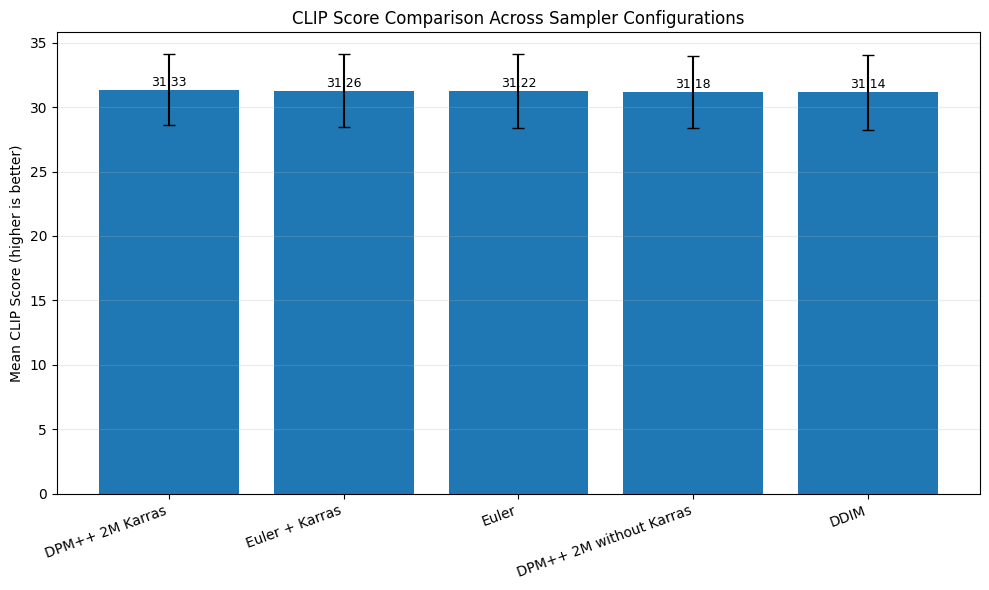

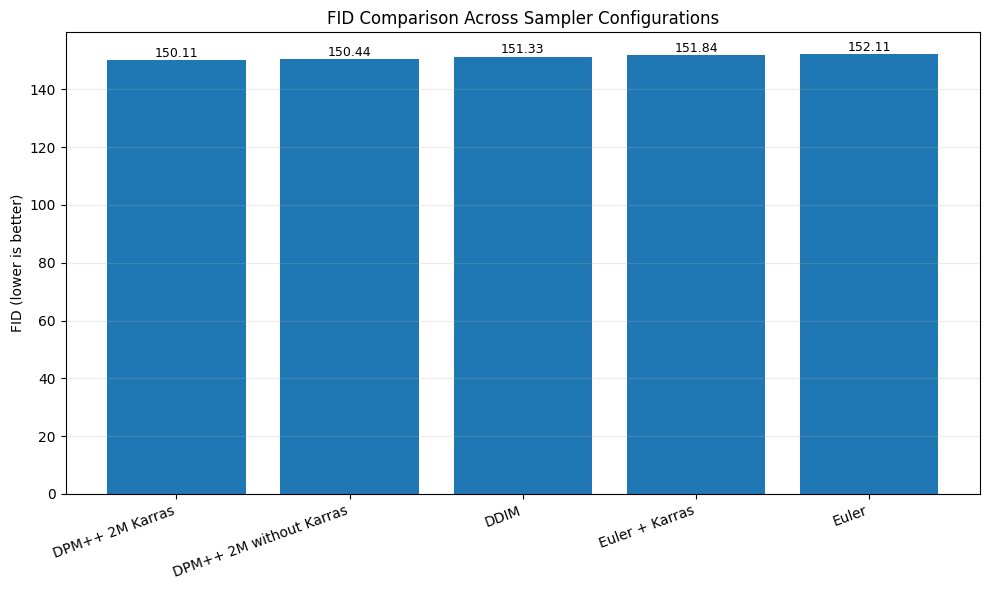

Files saved successfully:
/content/drive/MyDrive/CA6127_project/results/metrics/sampler_comparison_clip_score.png
/content/drive/MyDrive/CA6127_project/results/metrics/sampler_comparison_fid.png
/content/drive/MyDrive/CA6127_project/results/metrics/sampler_comparison_summary.csv


In [ ]:
# Step 7: Summarize the CLIP Score and FID of the five sampling configurations into two comparison plots.

import os
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = "/content/drive/MyDrive/CA6127_project"
METRICS_DIR = os.path.join(PROJECT_DIR, "results", "metrics")
os.makedirs(METRICS_DIR, exist_ok=True)

# 1. Combine main experiments and ablation experiments
results = pd.DataFrame([
    {
        "sampler": "DDIM",
        "clip_mean": 31.1400,
        "clip_std": 2.9246,
        "fid": 151.3286
    },
    {
        "sampler": "Euler",
        "clip_mean": 31.2203,
        "clip_std": 2.8617,
        "fid": 152.1145
    },
    {
        "sampler": "DPM++ 2M Karras",
        "clip_mean": 31.3307,
        "clip_std": 2.7582,
        "fid": 150.1101
    },
    {
        "sampler": "Euler + Karras",
        "clip_mean": 31.2572,
        "clip_std": 2.8319,
        "fid": 151.8379
    },
    {
        "sampler": "DPM++ 2M without Karras",
        "clip_mean": 31.1782,
        "clip_std": 2.7860,
        "fid": 150.4405
    }
])

# Save combined results
results.to_csv(
    os.path.join(METRICS_DIR, "sampler_comparison_summary.csv"),
    index=False
)

# 2. CLIP Score comparison
# Error bars represent standard deviation across 200 prompts.
clip_plot = results.sort_values("clip_mean", ascending=False)

plt.figure(figsize=(10, 6))
bars = plt.bar(
    clip_plot["sampler"],
    clip_plot["clip_mean"],
    yerr=clip_plot["clip_std"],
    capsize=4
)
plt.ylabel("Mean CLIP Score (higher is better)")
plt.title("CLIP Score Comparison Across Sampler Configurations")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, clip_plot["clip_mean"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.08,
        f"{value:.2f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
clip_path = os.path.join(
    METRICS_DIR, "sampler_comparison_clip_score.png"
)
plt.savefig(clip_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# 3. FID comparison
# Lower FID indicates better distributional similarity.
fid_plot = results.sort_values("fid", ascending=True)

plt.figure(figsize=(10, 6))
bars = plt.bar(fid_plot["sampler"], fid_plot["fid"])
plt.ylabel("FID (lower is better)")
plt.title("FID Comparison Across Sampler Configurations")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, fid_plot["fid"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.08,
        f"{value:.2f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
fid_path = os.path.join(
    METRICS_DIR, "sampler_comparison_fid.png"
)
plt.savefig(fid_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Files saved successfully:")
print(clip_path)
print(fid_path)
print(os.path.join(METRICS_DIR, "sampler_comparison_summary.csv"))


=== Generation Time Summary (30 steps) ===


,sampler,count,mean,median,std,min,max
0,ddim,200,5.4341,5.4702,0.1689,4.5216,5.9581
1,euler,200,5.4239,5.4422,0.1121,4.6883,5.5062
2,dpmpp,200,5.4353,5.4488,0.0718,4.8999,5.5143
3,euler_karras,200,5.4248,5.4267,0.0195,5.3639,5.4712
4,dpmpp_nokarras,200,5.3483,5.4178,0.2411,4.2785,5.6753


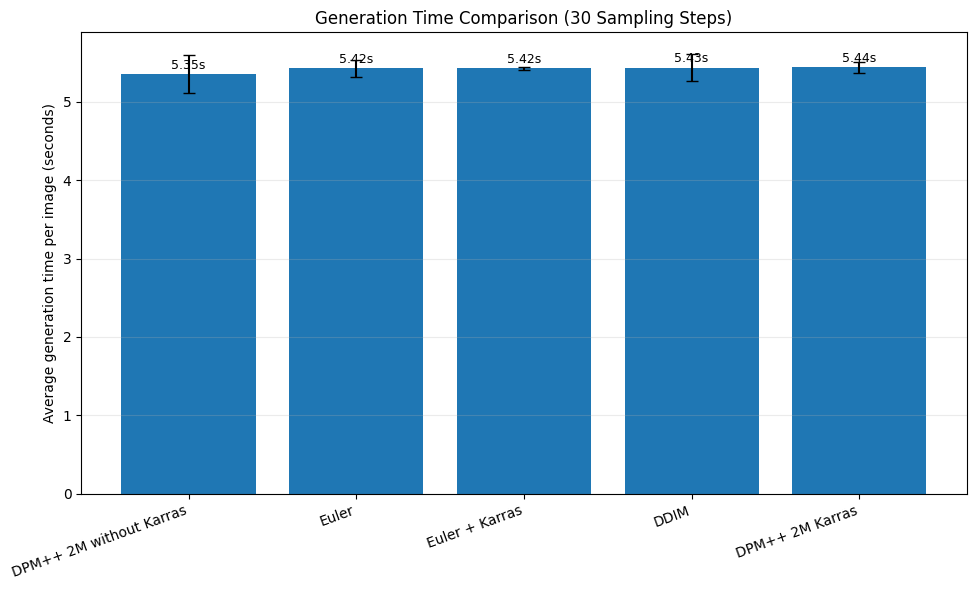

Saved: /content/drive/MyDrive/CA6127_project/results/metrics/sampler_generation_time_comparison.png


In [ ]:
# Step:8: Generation Speed Analysis
# Calculate the mean generation time, median, and standard deviation for the five 30-step configurations from generation_log.csv, and plot the speed comparison.

import os
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = "/content/drive/MyDrive/CA6127_project"
LOG_PATH = os.path.join(
    PROJECT_DIR, "results", "generation_log.csv"
)
METRICS_DIR = os.path.join(
    PROJECT_DIR, "results", "metrics"
)
os.makedirs(METRICS_DIR, exist_ok=True)

df = pd.read_csv(LOG_PATH)

# Compare all five configurations at 30 steps
samplers = [
    "ddim",
    "euler",
    "dpmpp",
    "euler_karras",
    "dpmpp_nokarras"
]

subset = df[
    df["sampler"].isin(samplers)
    & (df["steps"] == 30)
].copy()

summary = (
    subset.groupby("sampler")["gen_time_s"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        min="min",
        max="max"
    )
    .reindex(samplers)
    .reset_index()
)

print("=== Generation Time Summary (30 steps) ===")
display(summary.round(4))

summary.to_csv(
    os.path.join(METRICS_DIR, "sampler_generation_time_summary.csv"),
    index=False
)

# Plot average generation time
labels = {
    "ddim": "DDIM",
    "euler": "Euler",
    "dpmpp": "DPM++ 2M Karras",
    "euler_karras": "Euler + Karras",
    "dpmpp_nokarras": "DPM++ 2M without Karras"
}

plot_df = summary.copy()
plot_df["label"] = plot_df["sampler"].map(labels)
plot_df = plot_df.sort_values("mean")

plt.figure(figsize=(10, 6))
bars = plt.bar(
    plot_df["label"],
    plot_df["mean"],
    yerr=plot_df["std"],
    capsize=4
)

plt.ylabel("Average generation time per image (seconds)")
plt.title("Generation Time Comparison (30 Sampling Steps)")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, plot_df["mean"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.03,
        f"{value:.2f}s",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()

output_path = os.path.join(
    METRICS_DIR, "sampler_generation_time_comparison.png"
)
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Saved:", output_path)


In [ ]:
# Step 9.1: Check the experimental files for the five different sampling steps.

import json
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path("/content/drive/MyDrive/CA6127_project")
IMAGE_DIR = PROJECT_DIR / "results" / "images"

rows = []

for steps in [10, 20, 30, 40, 50]:
    folder = IMAGE_DIR / f"dpmpp_s{steps}"
    config_path = folder / "run_config.json"

    # 兼容 run_config.json 放在实验结果目录的情况
    if not config_path.exists():
        candidates = list(
            (PROJECT_DIR / "results").glob(
                f"**/dpmpp_s{steps}/run_config.json"
            )
        )
        if candidates:
            config_path = candidates[0]

    image_count = len(list(folder.glob("*.png"))) if folder.exists() else 0

    row = {
        "steps_expected": steps,
        "image_folder": str(folder),
        "image_count": image_count,
        "config_exists": config_path.exists(),
        "config_path": str(config_path)
    }

    if config_path.exists():
        with open(config_path, "r") as f:
            config = json.load(f)
        row["config"] = json.dumps(config, ensure_ascii=False)

    rows.append(row)

check_df = pd.DataFrame(rows)
display(check_df.drop(columns=["config"], errors="ignore"))

for row in rows:
    print(f"\n--- DPM++ {row['steps_expected']} steps ---")
    if row.get("config"):
        print(row["config"])
    else:
        print("Configuration file not found at the checked path.")


,steps_expected,image_folder,image_count,config_exists,config_path
0,10,/content/drive/MyDrive/CA6127_project/results/...,200,True,/content/drive/MyDrive/CA6127_project/results/...
1,20,/content/drive/MyDrive/CA6127_project/results/...,200,True,/content/drive/MyDrive/CA6127_project/results/...
2,30,/content/drive/MyDrive/CA6127_project/results/...,200,True,/content/drive/MyDrive/CA6127_project/results/...
3,40,/content/drive/MyDrive/CA6127_project/results/...,200,True,/content/drive/MyDrive/CA6127_project/results/...
4,50,/content/drive/MyDrive/CA6127_project/results/...,200,True,/content/drive/MyDrive/CA6127_project/results/...



--- DPM++ 10 steps ---
{"member_b_generation": 1, "model_id": "stable-diffusion-v1-5/stable-diffusion-v1-5", "model_revision": null, "reference_model_revision": null, "sampler": "dpmpp", "cfg": 7.5, "height": 512, "width": 512, "dtype": "float16", "safety_checker": null, "data": "data/captions.json", "scheduler_class": "DPMSolverMultistepScheduler", "scheduler_config": {"num_train_timesteps": 1000, "beta_start": 0.00085, "beta_end": 0.012, "beta_schedule": "scaled_linear", "trained_betas": null, "solver_order": 2, "prediction_type": "epsilon", "thresholding": false, "dynamic_thresholding_ratio": 0.995, "sample_max_value": 1.0, "algorithm_type": "dpmsolver++", "solver_type": "midpoint", "lower_order_final": true, "euler_at_final": false, "use_karras_sigmas": true, "use_exponential_sigmas": false, "use_beta_sigmas": false, "use_lu_lambdas": false, "use_flow_sigmas": false, "flow_shift": 1.0, "final_sigmas_type": "zero", "lambda_min_clipped": -Infinity, "variance_type": null, "timestep_s

In [ ]:
# Step 9.2: Calculate the CLIP Score for the five experiments with different sampling steps.
import json
import os
from pathlib import Path

import pandas as pd
import torch
from PIL import Image
from tqdm.auto import tqdm
from transformers import CLIPModel, CLIPProcessor

PROJECT_DIR = Path("/content/drive/MyDrive/CA6127_project")
IMAGE_DIR = PROJECT_DIR / "results" / "images"
CAPTIONS_PATH = PROJECT_DIR / "data" / "captions.json"
METRICS_DIR = PROJECT_DIR / "results" / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

# Load the 200 prompts
with open(CAPTIONS_PATH, "r") as f:
    captions = json.load(f)

prompt_by_id = {
    int(item["prompt_id"]): item["caption"]
    for item in captions
}

# Load CLIP
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Evaluation device:", device)

model_name = "openai/clip-vit-base-patch32"
processor = CLIPProcessor.from_pretrained(model_name)
model = CLIPModel.from_pretrained(model_name).to(device)
model.eval()

all_results = []

for steps in [10, 20, 30, 40, 50]:
    folder = IMAGE_DIR / f"dpmpp_s{steps}"
    image_paths = sorted(
        folder.glob("*.png"),
        key=lambda p: int(p.stem)
    )

    if len(image_paths) != 200:
        raise ValueError(
            f"{folder}: expected 200 images, found {len(image_paths)}"
        )

    print(f"\nEvaluating DPM++ {steps} steps: {len(image_paths)} images")

    for path in tqdm(image_paths):
        prompt_id = int(path.stem)
        caption = prompt_by_id[prompt_id]

        with Image.open(path) as im:
            image = im.convert("RGB")

        inputs = processor(
            text=[caption],
            images=[image],
            return_tensors="pt",
            padding=True,
            truncation=True
        )
        inputs = {k: v.to(device) for k, v in inputs.items()}

        with torch.no_grad():
            outputs = model(**inputs)
            image_emb = outputs.image_embeds
            text_emb = outputs.text_embeds

            image_emb = image_emb / image_emb.norm(
                dim=-1, keepdim=True
            )
            text_emb = text_emb / text_emb.norm(
                dim=-1, keepdim=True
            )

            similarity = (image_emb * text_emb).sum(dim=-1)
            clip_score = 100 * similarity.item()

        all_results.append({
            "prompt_id": prompt_id,
            "steps": steps,
            "caption": caption,
            "clip_score": clip_score
        })

per_image = pd.DataFrame(all_results)
per_image.to_csv(
    METRICS_DIR / "dpmpp_steps_clip_scores_per_image.csv",
    index=False
)

summary = (
    per_image.groupby("steps")["clip_score"]
    .agg(
        count="count",
        mean="mean",
        std="std",
        median="median"
    )
    .reset_index()
)

summary.to_csv(
    METRICS_DIR / "dpmpp_steps_clip_score_summary.csv",
    index=False
)

print("\n=== DPM++ CLIP Score by Sampling Steps ===")
display(summary.round(4))


Evaluation device: cuda


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

...

  0%|          | 0/200 [00:00<?, ?it/s]


Evaluating DPM++ 50 steps: 200 images


  0%|          | 0/200 [00:00<?, ?it/s]


=== DPM++ CLIP Score by Sampling Steps ===


,steps,count,mean,std,median
0,10,200,31.0289,2.6820,30.8685
1,20,200,31.3100,2.8218,31.1101
2,30,200,31.3307,2.7582,31.2791
3,40,200,31.2560,2.7798,31.2623
4,50,200,31.2653,2.7435,31.0996


In [ ]:
# Step 9.3: Calculate the FID and generation time for the five experiments with different sampling steps.

from pathlib import Path
import pandas as pd
from cleanfid import fid

PROJECT_DIR = Path("/content/drive/MyDrive/CA6127_project")
IMAGE_DIR = PROJECT_DIR / "results" / "images"
METRICS_DIR = PROJECT_DIR / "results" / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

# 1. FID for each sampling-step setting
real_dir = str(METRICS_DIR / "fid_reference_images")
fid_results = []

for steps in [10, 20, 30, 40, 50]:
    gen_dir = str(IMAGE_DIR / f"dpmpp_s{steps}")
    score = fid.compute_fid(
        real_dir,
        gen_dir,
        mode="clean"
    )
    fid_results.append({
        "steps": steps,
        "FID": score
    })
    print(f"DPM++ {steps} steps: FID = {score:.4f}")

fid_df = pd.DataFrame(fid_results)
fid_df.to_csv(
    METRICS_DIR / "dpmpp_steps_fid_summary.csv",
    index=False
)

# 2. Generation time for each step setting
log_df = pd.read_csv(
    PROJECT_DIR / "results" / "generation_log.csv"
)

timing_df = (
    log_df[
        (log_df["sampler"] == "dpmpp")
        & (log_df["steps"].isin([10, 20, 30, 40, 50]))
    ]
    .groupby("steps")["gen_time_s"]
    .agg(
        count="count",
        mean="mean",
        std="std",
        median="median"
    )
    .reset_index()
)

timing_df.to_csv(
    METRICS_DIR / "dpmpp_steps_generation_time.csv",
    index=False
)

# 3. Combine all three metrics
clip_df = pd.read_csv(
    METRICS_DIR / "dpmpp_steps_clip_score_summary.csv"
)

summary = (
    clip_df
    .merge(fid_df, on="steps")
    .merge(timing_df, on="steps")
)

summary = summary.rename(columns={
    "mean": "CLIP_mean",
    "std": "CLIP_std",
    "median": "CLIP_median"
})

summary.to_csv(
    METRICS_DIR / "dpmpp_steps_comparison_summary.csv",
    index=False
)

print("\n=== DPM++ Sampling Steps: Final Comparison ===")
display(summary.round(4))


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 12 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


compute FID between two folders
Found 200 images in the folder /content/drive/MyDrive/CA6127_project/results/metrics/fid_reference_images


FID fid_reference_images :   0%|          | 0/7 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 12 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
FID fid_reference_images : 100%|██████████| 7/7 [00:06<00:00,  1.03it/s]


Found 200 images in the folder /content/drive/MyDrive/CA6127_project/results/images/dpmpp_s10


FID dpmpp_s10 : 100%|██████████| 7/7 [00:13<00:00,  1.92s/it]


...

FID fid_reference_images : 100%|██████████| 7/7 [00:08<00:00,  1.20s/it]


Found 200 images in the folder /content/drive/MyDrive/CA6127_project/results/images/dpmpp_s50


FID dpmpp_s50 : 100%|██████████| 7/7 [00:07<00:00,  1.07s/it]


DPM++ 50 steps: FID = 150.2166

=== DPM++ Sampling Steps: Final Comparison ===


,steps,count_x,mean_x,std_x,median_x,FID,count_y,mean_y,std_y,median_y
0,10,200,31.0289,2.6820,30.8685,151.0797,200,1.7278,0.0591,1.7486
1,20,200,31.3100,2.8218,31.1101,151.4372,200,3.2796,0.0081,3.2792
2,30,200,31.3307,2.7582,31.2791,150.1103,200,5.4353,0.0718,5.4488
3,40,200,31.2560,2.7798,31.2623,151.5918,200,6.3449,0.0099,6.3452
4,50,200,31.2653,2.7435,31.0996,150.2166,200,7.8775,0.0109,7.8770


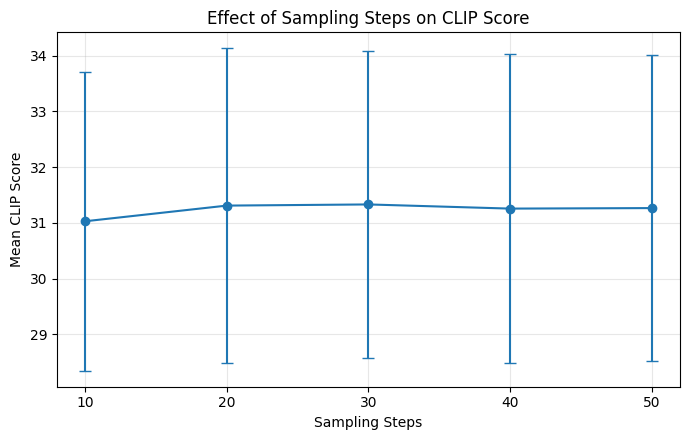

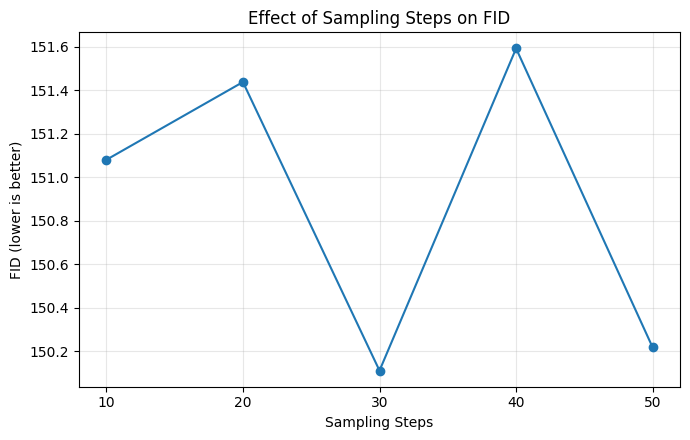

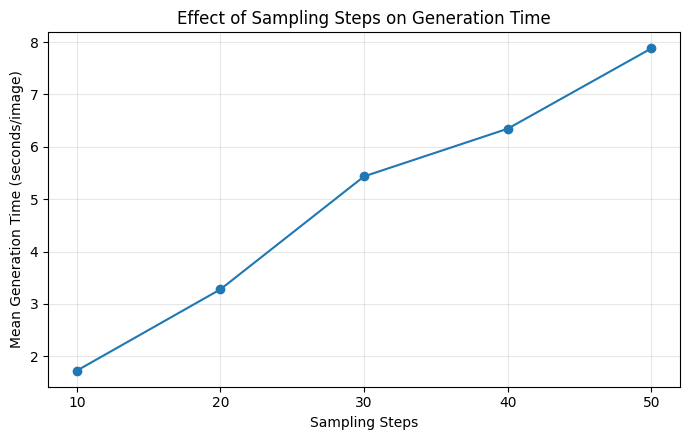

Figures saved to: /content/drive/MyDrive/CA6127_project/results/visualizations
1. dpmpp_steps_clip_score.png
2. dpmpp_steps_fid.png
3. dpmpp_steps_generation_time.png


In [ ]:
# Step 9.4: plot
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path("/content/drive/MyDrive/CA6127_project")
METRICS_DIR = PROJECT_DIR / "results" / "metrics"
VIZ_DIR = PROJECT_DIR / "results" / "visualizations"
VIZ_DIR.mkdir(parents=True, exist_ok=True)

# Load the existing experiment results
df = pd.read_csv(
    METRICS_DIR / "dpmpp_steps_comparison_summary.csv"
).sort_values("steps")

steps = df["steps"]
clip_mean = df["mean_x"]
clip_std = df["std_x"]
fid_scores = df["FID"]
gen_time = df["mean_y"]

# Figure 1: CLIP Score
plt.figure(figsize=(7, 4.5))
plt.errorbar(
    steps, clip_mean, yerr=clip_std,
    marker="o", capsize=4
)
plt.xlabel("Sampling Steps")
plt.ylabel("Mean CLIP Score")
plt.title("Effect of Sampling Steps on CLIP Score")
plt.xticks(steps)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    VIZ_DIR / "dpmpp_steps_clip_score.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

# Figure 2: FID
plt.figure(figsize=(7, 4.5))
plt.plot(steps, fid_scores, marker="o")
plt.xlabel("Sampling Steps")
plt.ylabel("FID (lower is better)")
plt.title("Effect of Sampling Steps on FID")
plt.xticks(steps)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    VIZ_DIR / "dpmpp_steps_fid.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

# Figure 3: Generation Time
plt.figure(figsize=(7, 4.5))
plt.plot(steps, gen_time, marker="o")
plt.xlabel("Sampling Steps")
plt.ylabel("Mean Generation Time (seconds/image)")
plt.title("Effect of Sampling Steps on Generation Time")
plt.xticks(steps)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    VIZ_DIR / "dpmpp_steps_generation_time.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

print("Figures saved to:", VIZ_DIR)
print("1. dpmpp_steps_clip_score.png")
print("2. dpmpp_steps_fid.png")
print("3. dpmpp_steps_generation_time.png")


In [ ]:

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/CA6127_project")

required_files = [
    "results/metrics/dpmpp_steps_clip_score_summary.csv",
    "results/metrics/dpmpp_steps_fid_summary.csv",
    "results/metrics/dpmpp_steps_generation_time.csv",
    "results/metrics/dpmpp_steps_comparison_summary.csv",
    "results/visualizations/dpmpp_steps_clip_score.png",
    "results/visualizations/dpmpp_steps_fid.png",
    "results/visualizations/dpmpp_steps_generation_time.png",
    "results/visualizations/sampler_comparison_8_prompts.png",
]

for rel_path in required_files:
    path = PROJECT_DIR / rel_path
    status = "OK" if path.exists() else "MISSING"
    print(f"[{status}] {rel_path}")


[OK] results/metrics/dpmpp_steps_clip_score_summary.csv
[OK] results/metrics/dpmpp_steps_fid_summary.csv
[OK] results/metrics/dpmpp_steps_generation_time.csv
[OK] results/metrics/dpmpp_steps_comparison_summary.csv
[OK] results/visualizations/dpmpp_steps_clip_score.png
[OK] results/visualizations/dpmpp_steps_fid.png
[OK] results/visualizations/dpmpp_steps_generation_time.png
[OK] results/visualizations/sampler_comparison_8_prompts.png


In [ ]:

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/CA6127_project")

for folder in [
    "results/metrics",
    "results/visualizations",
]:
    print(f"\n===== {folder} =====")
    for p in sorted((PROJECT_DIR / folder).glob("*")):
        if p.is_file():
            print(f"{p.name} ({p.stat().st_size / 1024:.1f} KB)")



===== results/metrics =====
ablation_clip_score_summary.csv (0.1 KB)
ablation_clip_scores_per_image.csv (15.2 KB)
ablation_fid_summary.csv (0.1 KB)
clip_score_summary.csv (0.1 KB)
clip_scores_per_image.csv (17.9 KB)
dpmpp_steps_clip_score_summary.csv (0.3 KB)
dpmpp_steps_clip_scores_per_image.csv (77.9 KB)
dpmpp_steps_comparison_summary.csv (0.7 KB)
dpmpp_steps_fid_summary.csv (0.1 KB)
dpmpp_steps_generation_time.csv (0.3 KB)
fid_summary.csv (0.2 KB)
sampler_comparison_clip_score.png (164.2 KB)
sampler_comparison_fid.png (159.0 KB)
sampler_comparison_summary.csv (0.2 KB)
sampler_generation_time_comparison.png (160.7 KB)
sampler_generation_time_summary.csv (0.4 KB)

===== results/visualizations =====
dpmpp_steps_clip_score.png (74.6 KB)
dpmpp_steps_fid.png (134.1 KB)
dpmpp_steps_generation_time.png (109.7 KB)
sampler_comparison_8_prompts.png (13383.2 KB)


In [ ]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path("/content/drive/MyDrive/CA6127_project")
METRICS_DIR = PROJECT_DIR / "results" / "metrics"

files = [
    "sampler_comparison_summary.csv",
    "clip_score_summary.csv",
    "fid_summary.csv",
    "ablation_clip_score_summary.csv",
    "ablation_fid_summary.csv",
    "sampler_generation_time_summary.csv",
    "dpmpp_steps_comparison_summary.csv",
]

for filename in files:
    path = METRICS_DIR / filename
    print(f"\n{'=' * 15} {filename} {'=' * 15}")

    if path.exists():
        df = pd.read_csv(path)
        print(df.to_string(index=False))
    else:
        print("FILE NOT FOUND")



=============== sampler_comparison_summary.csv ===============
                sampler  clip_mean  clip_std      fid
                   DDIM    31.1400    2.9246 151.3286
                  Euler    31.2203    2.8617 152.1145
        DPM++ 2M Karras    31.3307    2.7582 150.1101
         Euler + Karras    31.2572    2.8319 151.8379
DPM++ 2M without Karras    31.1782    2.7860 150.4405

=============== clip_score_summary.csv ===============
sampler  count    mean    std  median
   ddim    200 31.1400 2.9246 31.1716
  dpmpp    200 31.3307 2.7582 31.2791
  euler    200 31.2203 2.8617 30.9771

=============== fid_summary.csv ===============
sampler        fid  num_real_images  num_generated_images fid_mode
   ddim 151.328560              200                   200    clean
  euler 152.114459              200                   200    clean
  dpmpp 150.110145              200                   200    clean

=============== ablation_clip_score_summary.csv ===============
       sampler  count 

CLIP df columns: Index(['sampler', 'count', 'mean', 'std', 'median'], dtype='object')
FID df columns: Index(['sampler', 'fid', 'num_real_images', 'num_generated_images',
       'fid_mode'],
      dtype='object')
Ablation comparison plot successfully saved to: /content/drive/MyDrive/CA6127_project/results/metrics/karras_ablation_comparison.png


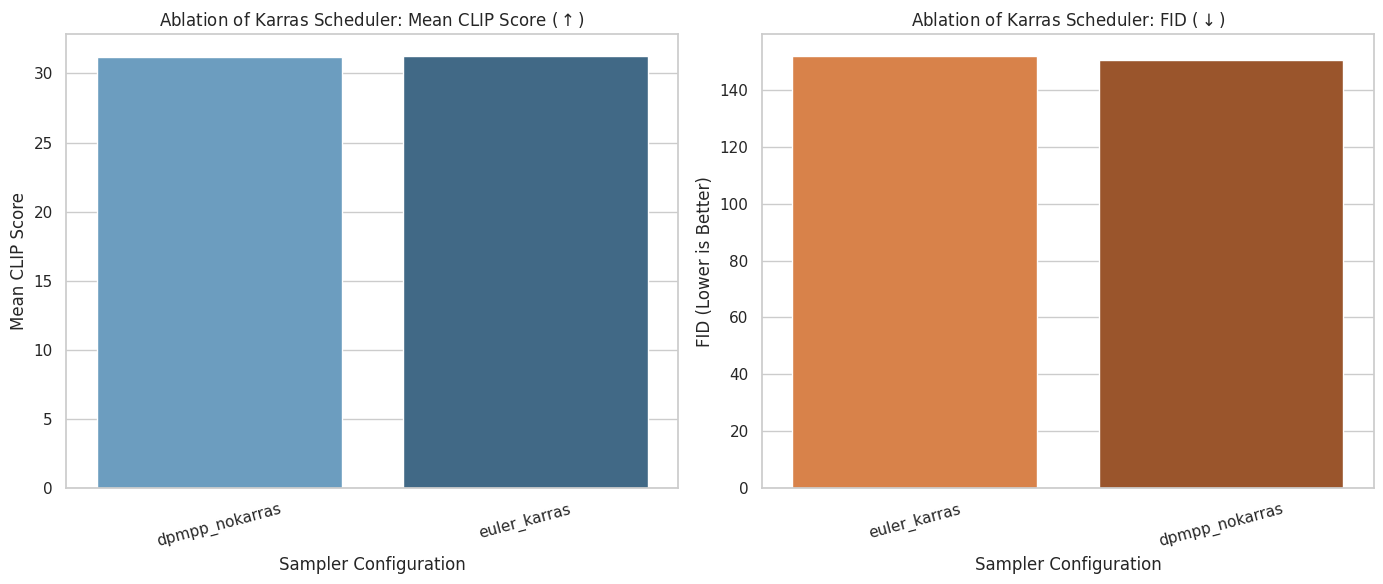

In [5]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 12})

# 1. Read CSV files
clip_df = pd.read_csv(
    '/content/drive/MyDrive/CA6127_project/results/metrics/ablation_clip_score_summary.csv'
)
fid_df = pd.read_csv(
    '/content/drive/MyDrive/CA6127_project/results/metrics/ablation_fid_summary.csv'
)

# Print columns to verify
print('CLIP df columns:', clip_df.columns)
print('FID df columns:', fid_df.columns)

# 2. Create figure and subplots for Karras ablation comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot CLIP Score comparison (using 'sampler' and 'mean' columns)
sns.barplot(
    data=clip_df,
    x='sampler',
    y='mean',
    hue='sampler',
    ax=axes[0],
    palette='Blues_d',
    legend=False,
)
axes[0].set_title(
    r'Ablation of Karras Scheduler: Mean CLIP Score ($\uparrow$)'
)
axes[0].set_ylabel('Mean CLIP Score')
axes[0].set_xlabel('Sampler Configuration')
axes[0].tick_params(axis='x', rotation=15)

# Plot FID comparison (using 'sampler' and 'fid' columns)
sns.barplot(
    data=fid_df,
    x='sampler',
    y='fid',
    hue='sampler',
    ax=axes[1],
    palette='Oranges_d',
    legend=False,
)
axes[1].set_title(r'Ablation of Karras Scheduler: FID ($\downarrow$)')
axes[1].set_ylabel('FID (Lower is Better)')
axes[1].set_xlabel('Sampler Configuration')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()

# 3. Save and display the plot
output_path = (
    '/content/drive/MyDrive/CA6127_project/results/metrics/karras_ablation_comparison.png'
)
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f'Ablation comparison plot successfully saved to: {output_path}')

plt.show()